# 02 · Preprocesamiento de datos

**Curso:** Análisis Computacional de Datos (DS3021) · **Proyecto ACD – Parte II** · **Responsable:** P1 · **Rama:** `p1-preprocesamiento`

## Objetivo
Dejar el dataset del catálogo de PlazaVea confiable para el análisis: fijar las cifras oficiales, buscar errores que no se ven a simple vista, marcar (sin borrar) los precios extremos, integrar tablas de apoyo, reducir la cardinalidad de las marcas y transformar variables. **Cada decisión se registra en una bitácora** (sección 8) con su justificación y la alternativa descartada.

| | |
|---|---|
| **Entrada** | `../data/processed/plazavea_limpio.csv` (corrida oficial del 22/09/2026) |
| **Salidas** | `../data/interim/plazavea_preprocesado.csv`, `../data/reference/dim_categoria.csv`, `../data/reference/dim_marca.csv`, `../docs/bitacora_decisiones.csv`, `../docs/cifras_oficiales.csv`, `../docs/evidencia_vendedor.csv` |
| **Ejecución** | Desde la carpeta `notebooks/`, de arriba hacia abajo |

## Técnicas usadas fuera de los laboratorios de clase (U3_L2 a U3_L6)
Todo lo demás (IQR, boxplot, dispersión, `merge` con `how="left"`, tratamiento de valores faltantes) corresponde a lo visto en clase. Estas tres técnicas se agregan porque el problema las exige:

| Técnica | Dónde | Por qué es necesaria |
|---|---|---|
| `log1p` | Sección 6 | El precio tiene una asimetría de 6,60: unos pocos productos muy caros dominan la media y los gráficos |
| Normalización min-max y z-score | Sección 6 (solo comparación) | Demuestran que reescalar no corrige la asimetría y justifican guardar solo `log1p` |
| Matriz de correlación | Sección 5 | Es la evidencia numérica para decidir qué columnas son redundantes |

## 0. Preparación del entorno

In [1]:
import re
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42                      # semilla fija para todo lo aleatorio
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

# Rutas relativas: ejecutar desde notebooks/
DATA = Path("../data")
DOCS = Path("../docs")
IN = DATA / "processed" / "plazavea_limpio.csv"
RAW_OFICIAL = DATA / "raw" / "plazavea_crudo_20260922_2046.csv"   # corrida oficial del grupo
OUT = DATA / "interim" / "plazavea_preprocesado.csv"
REF = DATA / "reference"
for carpeta in (OUT.parent, REF, DOCS):
    carpeta.mkdir(parents=True, exist_ok=True)

# --- Bitácora de decisiones (alimenta la sección 6 del informe) ---
bitacora = []
def log(paso, decision, justificacion, alternativa, filas_antes, filas_despues):
    bitacora.append({
        "paso": paso,
        "decision": decision,
        "justificacion": justificacion,
        "alternativa_descartada": alternativa,
        "filas_antes": filas_antes,
        "filas_despues": filas_despues,
        "delta_filas": filas_despues - filas_antes,
    })
    print(f"[{paso}] {decision}  |  filas: {filas_antes} -> {filas_despues}")

## 1. Auditoría de partida y cifras oficiales

Se parte del dataset inicial (resultado de la limpieza de la Parte I) y del crudo de la corrida oficial del **22/09/2026**, la única que usa el equipo. La tabla siguiente fija las cifras que se citan en el informe: **todo número del informe sale de aquí** (también queda en `../docs/cifras_oficiales.csv`).

In [2]:
df_inicial = pd.read_csv(IN)
raw = pd.read_csv(RAW_OFICIAL)
df = df_inicial.copy()          # trabajamos con una copia 

con_oferta = df[df["tiene_descuento"]]
cifras = {
    "Filas del crudo (corrida 22/09)": len(raw),
    "Filas del dataset inicial (limpio)": len(df_inicial),
    "Columnas del dataset inicial": df_inicial.shape[1],
    "url_imagen: nulos en el crudo (%)": round(raw["url_imagen"].isna().mean() * 100, 1),
    "Productos con descuento": int(df["tiene_descuento"].sum()),
    "Productos con descuento (%)": round(df["tiene_descuento"].mean() * 100, 1),
    "Descuentos menores a 10 % (% de los descuentos)": round((con_oferta["descuento_pct"] < 10).mean() * 100, 1),
    "Mediana del ahorro (S/, solo con oferta)": round(con_oferta["ahorro_soles"].median(), 2),
    "Productos con precio Oh!": int(df["tiene_precio_oh"].sum()),
    "Productos con precio Oh! (%)": round(df["tiene_precio_oh"].mean() * 100, 1),
    "Marcas distintas": df["marca"].nunique(),
    "Categorías": df["categoria"].nunique(),
    "Extracción (desde)": df["fecha_extraccion"].min(),
    "Extracción (hasta)": df["fecha_extraccion"].max(),
}
tabla_cifras = pd.Series(cifras, name="valor").to_frame()
tabla_cifras.to_csv(DOCS / "cifras_oficiales.csv")
tabla_cifras

,valor
Filas del crudo (corrida 22/09),1506
Filas del dataset inicial (limpio),1491
Columnas del dataset inicial,12
url_imagen: nulos en el crudo (%),72.4
Productos con descuento,718
Productos con descuento (%),48.2
Descuentos menores a 10 % (% de los descuentos),34.7
"Mediana del ahorro (S/, solo con oferta)",1.76
Productos con precio Oh!,96
Productos con precio Oh! (%),6.4


In [3]:
auditoria = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "nulos_%": (df.isna().mean() * 100).round(2),
    "valores_distintos": df.nunique(),
})
print("duplicados por url_producto:", df["url_producto"].duplicated().sum())
print("duplicados por id_producto :", df["id_producto"].duplicated().sum())
print("nombres repetidos (presentaciones distintas, no son duplicados):", df["nombre"].duplicated().sum())
print("\nproductos por categoría:")
print(df["categoria"].value_counts())
auditoria

duplicados por url_producto: 0
duplicados por id_producto : 0
nombres repetidos (presentaciones distintas, no son duplicados): 20

productos por categoría:
categoria
Abarrotes            150
Bebidas              150
Lácteos              150
Cuidado Personal     150
Frutas y Verduras    150
Carnes y Pescados    150
Desayunos            150
Quesos y Fiambres    149
Panadería            147
Congelados           145
Name: count, dtype: int64


,tipo,nulos,nulos_%,valores_distintos
id_producto,object,0,0.0,1491
nombre,object,0,0.0,1471
marca,object,0,0.0,277
categoria,object,0,0.0,10
precio_venta,float64,0,0.0,412
precio_regular,float64,0,0.0,383
tiene_precio_oh,bool,0,0.0,2
descuento_pct,float64,0,0.0,453
url_producto,object,0,0.0,1491
fecha_extraccion,object,0,0.0,49


**Lectura.** El dataset inicial tiene 1491 productos (el crudo tenía 1506; la diferencia son los 15 productos de la categoría Limpieza, excluida en la Parte I por extracción incompleta), 12 columnas y 10 categorías. No hay celdas vacías ni duplicados por `url_producto` ni por `id_producto`. Se deduplica por URL y no por nombre: hay 20 nombres repetidos que son presentaciones distintas de un mismo producto.

El 48,2 % de los productos tiene descuento, pero el 34,7 % de esos descuentos es menor a 10 % y la mediana del ahorro es de solo S/ 1,76: muchas ofertas son simbólicas. Solo 96 productos (6,4 %) tienen precio con tarjeta Oh!.

La tabla cuenta 277 marcas en el dataset inicial; al unificar `HORNIMAN S` con `HORNIMANS` (sección 2.2) quedan **276**, que es la cifra final de marcas.

Que no haya nulos no garantiza calidad. La sección 2 busca defectos que no aparecen como celdas vacías.

## 2. Limpieza: errores escondidos

Se revisan cuatro aspectos: precios imposibles o de relleno, coherencia entre las variables derivadas, marcas escritas de varias formas y la marca `GENÉRICO`.

### 2.1 Precios: rangos, coherencia y valores de relleno

In [4]:
pd.set_option("display.max_colwidth", None)   # muestra el texto completo de cada celda (URL incluidos)
print("precio_venta   min/max:", df["precio_venta"].min(), df["precio_venta"].max())
print("precio_regular min/max:", df["precio_regular"].min(), df["precio_regular"].max())
print("precios <= 0:", int((df[["precio_venta", "precio_regular"]] <= 0).sum().sum()))
print("precio_regular < precio_venta:", int((df["precio_regular"] < df["precio_venta"]).sum()))

print("\nlos 10 precios más altos (¿relleno o reales?):")
display(df.nlargest(10, "precio_venta")[["nombre", "categoria", "precio_venta", "precio_regular", "url_producto"]])

print("\nURL a verificar a mano (producto con el precio más alto):")
for _, fila in df.nlargest(1, "precio_venta").iterrows():
    print(f"  {fila['nombre']}  ->  {fila['url_producto']}")

print("precios que más se repiten (posibles valores de relleno):")
display(df["precio_venta"].value_counts().head(10).rename("n_productos").to_frame())

precio_venta   min/max: 0.9 999.0
precio_regular min/max: 0.9 999.0
precios <= 0: 0
precio_regular < precio_venta: 0

los 10 precios más altos (¿relleno o reales?):


,nombre,categoria,precio_venta,precio_regular,url_producto
488,Secador Alisador SIEGEN SG-B500 Blanco,Cuidado Personal,999.0,999.0,https://www.plazavea.com.pe/secador-alisador-siegen-sgb500-blanco-20570733/p
521,Candiseptic® Kit - NaturalSlim,Cuidado Personal,629.0,699.0,https://www.plazavea.com.pe/candiseptic-kit-naturalslim-100920101/p
595,Proteína Gold standard isolate 5lb Chocolate O...,Cuidado Personal,529.0,610.0,https://www.plazavea.com.pe/proteina-gold-standard-isolate-5lb-chocolate-optimum-nutrition-101791409/p
593,Nordic Naturals Ultimate Omega 2840mg Omega 3 ...,Cuidado Personal,429.0,549.0,https://www.plazavea.com.pe/nordic-naturals-ultimate-omega-2840mg-omega-3-premium-epa-dha-237ml-sabor-limon-101966815/p
588,Nordic Naturals Ultimate Omega 2X 2150mg EPA D...,Cuidado Personal,419.0,499.0,https://www.plazavea.com.pe/nordic-naturals-ultimate-omega-2x-2150mg-epa-dha-90-softgels-102026747/p
522,Zeaxan 6 Pack Cuidado para Tu Salud Ocular,Cuidado Personal,382.0,894.0,https://www.plazavea.com.pe/zeaxan-6-pack-cuidado-para-tu-salud-ocular-100889693/p
598,CALMANO - 6 pack - CAPSULAS para VARICES y HEM...,Cuidado Personal,382.0,894.0,https://www.plazavea.com.pe/calmano-6-pack-capsulas-para-varices-y-hemorroides-101679450/p
599,CALMANO capsulas pack x 3 + CALMANO crema pack...,Cuidado Personal,382.0,894.0,https://www.plazavea.com.pe/calmano-capsulas-pack-x-3-calmano-crema-pack-x-3-101679449/p
589,UNIVERSE NUTRITION ISO WHEY 90 5 KG. CHOCOLATE...,Cuidado Personal,379.9,409.9,https://www.plazavea.com.pe/universe-nutrition-iso-whey-90-5-kg-chocolate-shaker-102026156/p
590,UNIVERSE NUTRITION ISO WHEY 90 5 KG. VAINILLA ...,Cuidado Personal,379.9,409.9,https://www.plazavea.com.pe/universe-nutrition-iso-whey-90-5-kg-vainilla-shaker-102023767/p



URL a verificar a mano (producto con el precio más alto):
  Secador Alisador SIEGEN SG-B500 Blanco  ->  https://www.plazavea.com.pe/secador-alisador-siegen-sgb500-blanco-20570733/p
precios que más se repiten (posibles valores de relleno):


,n_productos
precio_venta,
6.9,33
7.9,32
9.5,25
13.9,25
9.9,24
16.9,23
7.5,22
8.9,22
12.9,22


**Resultado.** No hay precios menores o iguales a cero ni casos con precio regular menor al de venta. Los precios que más se repiten (S/ 6,90, 7,90, 9,50…) son precios comerciales habituales, con entre 22 y 33 productos cada uno: no hay señales de valores de relleno.

El precio más alto, **S/ 999,00** (un secador de cabello SIEGEN), tiene precio de venta igual al regular. Se verificó a mano en la página del producto (23/10/2026): es un precio real: la página lo muestra como «Vendido y despachado por: Plaza Vea» y ofrece calcular cuotas con la tarjeta SIP. **Decisión:** se conserva; no se trata como valor centinela. En la sección 3 queda marcado como precio extremo, pero no se elimina.

In [5]:
# Coherencia entre variables derivadas: se recalculan desde los precios y se comparan
hay_oferta = df["precio_regular"] > df["precio_venta"]
desc_recalc = np.where(hay_oferta, (1 - df["precio_venta"] / df["precio_regular"]) * 100, 0.0).round(2)
ahorro_recalc = (df["precio_regular"] - df["precio_venta"]).round(2)

incoherencias = {
    "tiene_descuento != (regular > venta)": int((hay_oferta != df["tiene_descuento"]).sum()),
    "descuento_pct distinto del recalculado": int((np.abs(desc_recalc - df["descuento_pct"]) > 0.01).sum()),
    "ahorro_soles distinto del recalculado": int((np.abs(ahorro_recalc - df["ahorro_soles"]) > 0.01).sum()),
}
pd.Series(incoherencias, name="casos").to_frame()

,casos
tiene_descuento != (regular > venta),0
descuento_pct distinto del recalculado,0
ahorro_soles distinto del recalculado,0


**Resultado.** Las tres variables derivadas (`tiene_descuento`, `descuento_pct` y `ahorro_soles`) coinciden con el recálculo desde los precios: 0 incoherencias. No hace falta corregir nada; el control queda registrado y se repite en el pipeline.

In [6]:
log("2.1 Verificación de precios y coherencia",
    "Sin cambios: no hay precios <= 0 ni regular < venta, y las 3 variables derivadas coinciden con el recálculo",
    "El control queda registrado; se repite en el pipeline para detectar errores de extracción futuros",
    "Recalcular y sobrescribir las columnas (innecesario: 0 diferencias)",
    len(df), len(df))

[2.1 Verificación de precios y coherencia] Sin cambios: no hay precios <= 0 ni regular < venta, y las 3 variables derivadas coinciden con el recálculo  |  filas: 1491 -> 1491


In [7]:
fila_max = df.loc[df["precio_venta"].idxmax()]
log("2.1.1 Verificación del precio máximo",
    f"Se conserva '{fila_max['nombre']}' (S/ {fila_max['precio_venta']:.2f}): es un precio real, no un valor de relleno",
    "Verificación manual en la página del producto (P1, 23/10/2026): vendido y despachado por Plaza Vea; precio de venta igual al regular, con opción de cuotas mediante tarjeta SIP",
    "Tratarlo como valor centinela y convertirlo en nulo (descartado: el producto y su precio existen)",
    len(df), len(df))

[2.1.1 Verificación del precio máximo] Se conserva 'Secador Alisador SIEGEN SG-B500 Blanco' (S/ 999.00): es un precio real, no un valor de relleno  |  filas: 1491 -> 1491


### 2.2 Marcas escritas de varias formas

Una misma marca escrita de dos formas se contaría como dos marcas y distorsionaría los rankings y la agrupación. Para detectarlas se compara una clave normalizada (sin tildes, signos ni distinción de mayúsculas).

In [8]:
def clave_marca(texto):
    """Clave de comparación: sin tildes, sin signos, en mayúsculas (BELL'S == BELLS == Bell s)."""
    t = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return re.sub(r"[^A-Z0-9]", "", t.upper())

agrupadas = df.groupby(df["marca"].map(clave_marca))["marca"].agg(lambda s: sorted(s.unique()))
variantes = agrupadas[agrupadas.map(len) > 1]
print("claves con más de una escritura:", len(variantes))
display(variantes.to_frame("escrituras_distintas"))

print("familias de marca (misma raíz, distinto sufijo):")
display(df.loc[df["marca"].str.contains("BELL", na=False), "marca"].value_counts().to_frame("n_productos"))

claves con más de una escritura: 1


,escrituras_distintas
marca,
HORNIMANS,"[HORNIMAN S, HORNIMANS]"


familias de marca (misma raíz, distinto sufijo):


,n_productos
marca,
BELL'S,111
BELL'S FRESCOS,23
BELL'S SELECCIÓN,2


**Resultado.** Solo se detecta un caso: `HORNIMAN S` y `HORNIMANS`, que son la misma marca (4 productos en total). Las tres escrituras de la familia BELL'S (`BELL'S`, `BELL'S FRESCOS`, `BELL'S SELECCIÓN`) no son errores: son líneas distintas que el propio sitio rotula así.

**Decisión.** `HORNIMAN S` se unifica con `HORNIMANS`, la forma más frecuente. Las líneas de BELL'S se mantienen separadas en `marca` y las tres se tratan como marca propia en la sección 4.3.

In [9]:
# Se unifica solo lo que colapsa por clave (misma marca con distinta escritura): se queda la forma más frecuente
frecuencia = df["marca"].value_counts()
mapa_marca = {}
for _, escrituras in variantes.items():
    canonica = max(escrituras, key=lambda m: frecuencia[m])
    for m in escrituras:
        mapa_marca[m] = canonica

n_cambiadas = int(df["marca"].isin([m for m, c in mapa_marca.items() if m != c]).sum())
df["marca"] = df["marca"].replace(mapa_marca)
print("Marcas unificadas (original -> canónica):", {m: c for m, c in mapa_marca.items() if m != c})

log("2.2.1 Unificación de marcas",
    f"Se unifican {len(variantes)} marca(s) con distintas escrituras ({n_cambiadas} filas afectadas); GENÉRICO se conserva",
    "Una misma marca escrita de dos formas contaría como dos marcas y distorsiona el ranking y la agrupación",
    "Unificar también las familias BELL'S (se pierde la distinción entre fresco y envasado)",
    len(df), len(df))

Marcas unificadas (original -> canónica): {'HORNIMAN S': 'HORNIMANS'}
[2.2.1 Unificación de marcas] Se unifican 1 marca(s) con distintas escrituras (1 filas afectadas); GENÉRICO se conserva  |  filas: 1491 -> 1491


### 2.3 La marca `GENÉRICO`

El sitio muestra el valor `GENÉRICO` en algunos productos. No es una marca ni un dato faltante, así que antes de decidir qué hacer con él se caracteriza qué son estos productos.

In [10]:
# Perfil de la marca GENÉRICO: ¿qué son estos productos y en qué se diferencian del resto?
es_gen = df["marca"].eq("GENÉRICO")   # coincidencia exacta (con contains("GEN") también caerían SIEGEN, HÄAGEN DAZS, etc.)
gen, resto = df[es_gen], df[~es_gen]
print(f"productos GENÉRICO: {len(gen)} ({len(gen) / len(df) * 100:.1f} %) | categorías: {gen['categoria'].value_counts().to_dict()}")
print(f"mediana de precio_venta : GENÉRICO S/ {gen['precio_venta'].median():.2f}  vs  resto S/ {resto['precio_venta'].median():.2f}")
print(f"% con descuento         : GENÉRICO {gen['tiene_descuento'].mean() * 100:.1f} %  vs  resto {resto['tiene_descuento'].mean() * 100:.1f} %")
print(f"con precio Oh!          : GENÉRICO {int(gen['tiene_precio_oh'].sum())} de {len(gen)}")
ranking = df["marca"].value_counts()
print(f"posición por frecuencia : {ranking.index.get_loc('GENÉRICO') + 1} de {len(ranking)} marcas")
print("\nejemplos de nombres:")
display(gen[["nombre", "categoria", "precio_venta", "url_producto"]].head(8))

productos GENÉRICO: 21 (1.4 %) | categorías: {'Cuidado Personal': 21}
mediana de precio_venta : GENÉRICO S/ 189.90  vs  resto S/ 10.90
% con descuento         : GENÉRICO 90.5 %  vs  resto 47.6 %
con precio Oh!          : GENÉRICO 0 de 21
posición por frecuencia : 14 de 276 marcas

ejemplos de nombres:


,nombre,categoria,precio_venta,url_producto
458,Mochila De Emergencia 30Lt Cinta Reflectiva,Cuidado Personal,71.00,https://www.plazavea.com.pe/mochila-de-emergencia-30lt-cinta-reflectiva-101197649/p
459,Mochila de Emergencia Naranja,Cuidado Personal,59.99,https://www.plazavea.com.pe/mochila-de-emergencia-naranja-101089166/p
460,Mochila de Emergencia Roja,Cuidado Personal,59.99,https://www.plazavea.com.pe/mochila-de-emergencia-roja-101089164/p
466,HAIREX para Caida de Cabello 3 Pack,Cuidado Personal,267.00,https://www.plazavea.com.pe/hairex-para-caida-de-cabello-3-pack-100882427/p
467,"Magnesol Polvo Efervescente, Naranja",Cuidado Personal,30.90,https://www.plazavea.com.pe/magnesol-polvo-efervescente-naranja-100509696/p
510,COLAGENO RENOVA CON BIOPEPTIDOS ACTIVOS,Cuidado Personal,120.00,https://www.plazavea.com.pe/colageno-renova-con-biopeptidos-activos-101930062/p
513,Pack Ashwagandh & Citrato De Magnesio + Resver...,Cuidado Personal,50.00,https://www.plazavea.com.pe/pack-ashwagandh-citrato-de-magnesio-resveratrol-100-capsulas-101492467/p
519,Aceite de pescado Omega 3 4200 mg 180 capsulas...,Cuidado Personal,239.00,https://www.plazavea.com.pe/aceite-de-pescado-omega-3-4200-mg-180-capsulas-blandas-naturabell-100945061/p


**Resultado.** Son 21 productos (1,4 %), todos de Cuidado Personal: suplementos y vitaminas, y 3 mochilas de emergencia. Su mediana de precio es S/ 189,90 frente a S/ 10,90 del resto, y el 90,5 % tiene descuento (47,6 % en el resto). Ninguno tiene precio Oh!. Como es la marca número 14 por frecuencia, entraría al top 30 y aparecería en los rankings como si fuera una marca real.

#### 2.3.1 Verificación manual: ¿quién vende estos productos?
Se abrieron a mano los 21 enlaces `GENÉRICO` y una muestra de 25 productos más: 10 de Cuidado Personal con mayor ahorro, 10 aleatorios de Cuidado Personal (semilla 42) y 5 de control de otras categorías. La evidencia queda en `../docs/evidencia_vendedor.csv` para que cualquiera pueda comprobarla.

In [11]:
EVID = DOCS / "evidencia_vendedor.csv"
assert EVID.exists(), "falta docs/evidencia_vendedor.csv (evidencia de la verificación manual)"
ev = pd.read_csv(EVID).fillna("")
resumen_vendedor = ev.groupby(["grupo", "vendido_por"]).size().unstack(fill_value=0)
display(resumen_vendedor)

def terceros(prefijo):
    sub = ev[ev["grupo"].str.startswith(prefijo)]
    return int((sub["vendido_por"] == "Tercero").sum()), len(sub)

t_gen, n_gen_rev = terceros("GENÉRICO")
t_a, n_a = terceros("A.")
t_b, n_b = terceros("B.")
t_c, n_c = terceros("C.")

log("2.3 Verificación manual de GENÉRICO",
    f"GENÉRICO se conserva en marca: {t_gen} de {n_gen_rev} productos revisados son vendidos por terceros. "
    f"Muestra en Cuidado Personal (sin GENÉRICO): {t_a} de {n_a} de mayores ahorros y {t_b} de {n_b} aleatorios son de terceros; "
    f"control en otras categorías: {t_c} de {n_c}",
    "Es un valor que muestra el sitio, no un dato faltante. Cada producto de terceros tiene una marca real distinta (prácticamente una marca por producto), "
    "así que recuperarlas no aporta a comparaciones ni a marca_agrupada y rompería la reproducibilidad (valores escritos a mano fuera del flujo). "
    "Las 3 mochilas de emergencia tienen 3 marcas distintas, ninguna es EMERGENCY KIT PERÚ",
    "Convertir a nulo (groupby ignora los nulos sin avisar), renombrar a SIN MARCA, recuperar la marca a mano o borrar las 21 filas",
    len(df), len(df))

vendido_por,PlazaVea,Tercero
grupo,,
A. Mayores ahorros (Cuidado Personal),1,9
B. Aleatorios de Cuidado Personal,4,6
C. Control: otras categorías,5,0
GENÉRICO (todos los productos),0,21


[2.3 Verificación manual de GENÉRICO] GENÉRICO se conserva en marca: 21 de 21 productos revisados son vendidos por terceros. Muestra en Cuidado Personal (sin GENÉRICO): 9 de 10 de mayores ahorros y 6 de 10 aleatorios son de terceros; control en otras categorías: 0 de 5  |  filas: 1491 -> 1491


**Resultado.** Los 21 productos `GENÉRICO` son vendidos por terceros y cada uno tiene una marca real distinta (prácticamente una marca por producto; las 3 mochilas tienen 3 marcas diferentes). En la muestra de Cuidado Personal, 9 de 10 productos de mayor ahorro y 6 de 10 productos aleatorios son de terceros; en las demás categorías, 0 de 5. Son muestras pequeñas: se toman como evidencia orientativa, no como un porcentaje de la categoría.

**Decisión sobre `GENÉRICO`:**
1. Se conserva el valor en `marca`, tal como lo muestra el sitio. No se convierte en nulo (los `groupby` ignorarían esas filas sin avisar) ni se borran las filas.
2. No se recuperan las marcas reales: serían unas 21 marcas con un solo producto, sin utilidad para comparar y fuera del flujo reproducible.
3. En `marca_agrupada` queda como nivel propio, fuera del top 30 (sección 5).
4. No debe usarse en rankings de marca ni en comparaciones de marcas (objetivo 5).

**Implicancia para el proyecto.** El catálogo mezcla productos de PlazaVea y de vendedores externos, y el dataset no tiene una columna de vendedor. Se declara como limitación.

## 3. Outliers de precio: se marcan, no se borran

Los productos caros (suplementos y electrodomésticos en Cuidado Personal, cortes premium en Carnes y Pescados) son **reales**: borrarlos eliminaría información. Se marcan con `es_outlier_precio` para que P3 y P4 decidan cómo tratarlos.

La técnica es la vista en clase (U3_L5): regla IQR, con límites Q1 − 1,5·IQR y Q3 + 1,5·IQR, apoyada en boxplot y gráfico de dispersión. La única variación es que se aplica **dentro de cada categoría**, porque un kilo de papa y un suplemento no son comparables.

In [12]:
def limites_iqr(serie, k=1.5):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

# Comparación: IQR global vs IQR por categoría
_, sup_global = limites_iqr(df["precio_venta"])
out_global = df["precio_venta"] > sup_global

def fuera_de_limites(serie):
    inf, sup = limites_iqr(serie)
    return (serie < inf) | (serie > sup)

out_categoria = df.groupby("categoria")["precio_venta"].transform(fuera_de_limites)

print(f"IQR global: límite superior S/ {sup_global:.2f} -> {int(out_global.sum())} productos")
print(f"IQR por categoría: {int(out_categoria.sum())} productos")
print("\noutliers del IQR global por categoría:")
print(df[out_global]["categoria"].value_counts().to_string())

IQR global: límite superior S/ 39.70 -> 159 productos
IQR por categoría: 64 productos

outliers del IQR global por categoría:
categoria
Cuidado Personal     122
Carnes y Pescados     22
Desayunos              4
Congelados             4
Abarrotes              2
Bebidas                2
Lácteos                2
Panadería              1


**Resultado.** Con un único límite global (S/ 39,70) se marcarían 159 productos, 122 de ellos de Cuidado Personal: el criterio castiga a toda la categoría y no detecta nada dentro de ella. Con el límite por categoría se marcan 64 productos, repartidos en las 10 categorías.

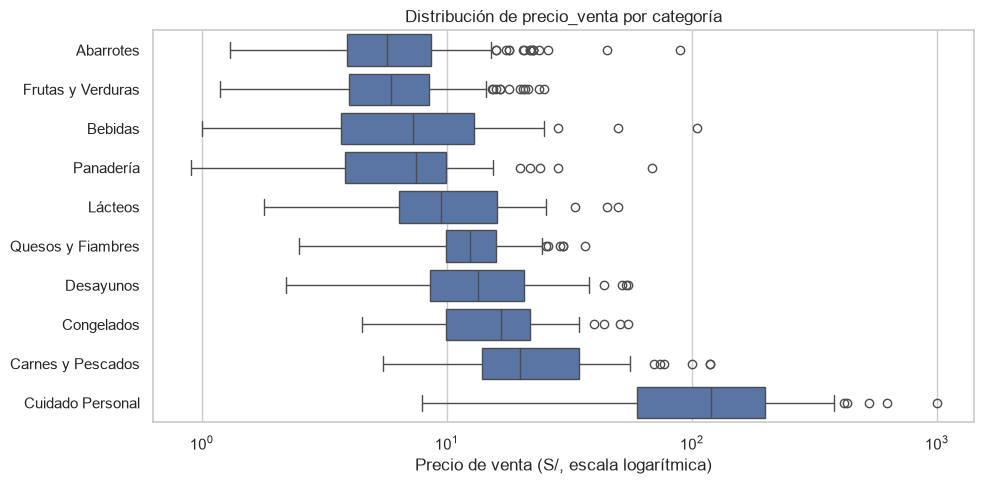

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))
orden = df.groupby("categoria")["precio_venta"].median().sort_values().index
sns.boxplot(data=df, y="categoria", x="precio_venta", order=orden, ax=ax)
ax.set_xscale("log")
ax.set_title("Distribución de precio_venta por categoría")
ax.set_xlabel("Precio de venta (S/, escala logarítmica)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Interpretación.** Cuidado Personal tiene la mediana más alta (S/ 119,90) y la mayor dispersión (IQR de S/ 139,10, con un máximo de S/ 999). El resto de categorías tiene medianas entre S/ 5,70 (Abarrotes) y S/ 19,90 (Carnes y Pescados). Un umbral global trataría como atípico lo que en Cuidado Personal es normal; por eso el límite se calcula dentro de cada categoría.

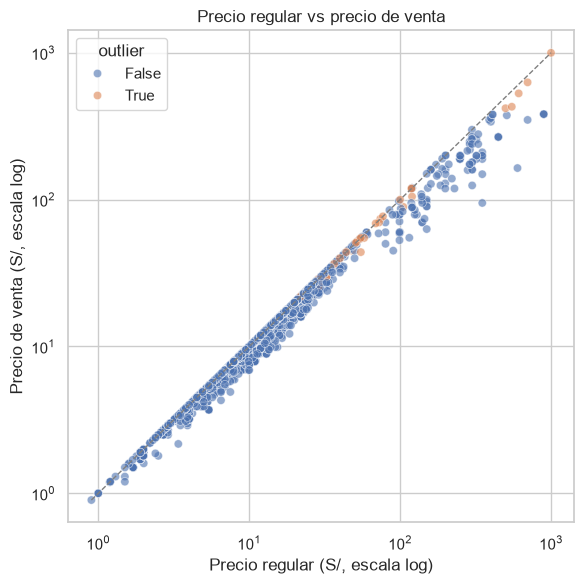

In [14]:
# Bivariado: precio regular vs precio de venta (los puntos sobre la diagonal tienen descuento)
fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(data=df, x="precio_regular", y="precio_venta", hue=out_categoria.rename("outlier"),
                alpha=0.6, ax=ax)
lim = [df["precio_regular"].min(), df["precio_regular"].max()]
ax.plot(lim, lim, color="gray", linestyle="--", linewidth=1)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_title("Precio regular vs precio de venta")
ax.set_xlabel("Precio regular (S/, escala log)")
ax.set_ylabel("Precio de venta (S/, escala log)")
plt.tight_layout()
plt.show()

**Interpretación.** Todos los puntos están sobre o debajo de la diagonal: el precio de venta nunca supera al regular, y los puntos que se separan de ella son los 718 productos con descuento. Los productos marcados como precio extremo no se distinguen por tener más descuento (37,5 % de ellos tiene descuento, frente a 48,6 % del resto): son simplemente productos caros.

In [15]:
df["es_outlier_precio"] = out_categoria.astype(bool)

# Efecto de los outliers: media vs mediana con y sin ellos
def efecto(g):
    sin = g.loc[~df.loc[g.index, "es_outlier_precio"]]
    return pd.Series({
        "n": len(g), "n_outliers": int(df.loc[g.index, "es_outlier_precio"].sum()),
        "media_con": g.mean(), "media_sin": sin.mean(),
        "mediana_con": g.median(), "mediana_sin": sin.median(),
    })

efecto_outliers = df.groupby("categoria")["precio_venta"].apply(lambda g: efecto(g)).unstack().round(2).astype({"n": int, "n_outliers": int})
display(efecto_outliers)

log("3. Marcar outliers de precio",
    f"Nueva columna es_outlier_precio (IQR por categoría, k = 1.5): {int(df['es_outlier_precio'].sum())} productos marcados, 0 eliminados",
    "Son productos reales del catálogo; el IQR por categoría evita que Cuidado Personal marque como atípico lo que es normal en otras categorías",
    f"Eliminarlos (pierde información real) o usar el IQR global ({int(out_global.sum())} marcados, casi todos de Cuidado Personal)",
    len(df), len(df))

,n,n_outliers,media_con,media_sin,mediana_con,mediana_sin
categoria,,,,,,
Abarrotes,150,16,8.07,5.89,5.70,4.90
Bebidas,150,3,9.64,8.59,7.25,6.90
Carnes y Pescados,150,6,26.18,23.40,19.90,19.50
Congelados,145,4,16.82,15.95,16.70,16.59
Cuidado Personal,150,5,149.75,134.19,119.90,119.00
Desayunos,150,4,15.57,14.59,13.45,13.10
Frutas y Verduras,150,12,7.11,6.07,5.93,5.54
Lácteos,150,3,11.75,11.12,9.50,9.50
Panadería,147,5,8.04,7.18,7.50,7.50


[3. Marcar outliers de precio] Nueva columna es_outlier_precio (IQR por categoría, k = 1.5): 64 productos marcados, 0 eliminados  |  filas: 1491 -> 1491


**Interpretación.** Los productos marcados elevan la media global de S/ 24,19 a S/ 26,68 (+10 %), pero la mediana casi no cambia (de S/ 10,70 a S/ 11,00). Por categoría, la media sube entre 5,5 % (Congelados, Quesos y Fiambres) y 37 % (Abarrotes), mientras que la mediana cambia como máximo 16,3 % (también Abarrotes). La mediana es, por lo tanto, la medida más estable para resumir precios.

**Decisión.** Se crea `es_outlier_precio` (64 productos) y no se elimina ninguna fila. El producto de S/ 999 queda marcado. P3 y P4 pueden analizar con o sin estos productos; se recomienda reportar la mediana junto a la media.

### 3.1 Otras variables: `descuento_pct` y `ahorro_soles`
También son asimétricas. Se mide cuántos casos superan el límite IQR, solo entre productos con oferta, sin crear una columna nueva.

In [16]:
for col in ["descuento_pct", "ahorro_soles"]:
    solo_oferta = df.loc[df["tiene_descuento"], col]
    inf, sup = limites_iqr(solo_oferta)
    print(f"{col:14s} (solo con oferta): límite superior {sup:8.2f} -> {int((solo_oferta > sup).sum())} casos sobre el límite")

descuento_pct  (solo con oferta): límite superior    39.09 -> 37 casos sobre el límite
ahorro_soles   (solo con oferta): límite superior     9.10 -> 107 casos sobre el límite


**Interpretación.** 37 de 718 descuentos superan el límite de 39,09 % y 107 de 718 ahorros superan los S/ 9,10; el mayor ahorro es de S/ 512. No se marcan en una columna porque los descuentos altos y los ahorros grandes son justamente lo que P3 analiza en los objetivos 3 y 4, no errores de datos. Los 5 mayores ahorros son todos de Cuidado Personal.

## 4. Integración: tablas de apoyo

Hay **una sola fuente** (una corrida de scraping), así que la integración consiste en: **(a)** reconciliar el crudo con el dataset inicial y **(b)** crear dos tablas de referencia y unirlas con *left join*, verificando que no se pierdan ni se dupliquen filas (identificación de entidades y claves, visto en U3_L6).

### 4.1 Reconciliación crudo → inicial

In [17]:
parciales = sorted((DATA / "raw").glob("parcial_*.csv"))
print(f"archivos parciales encontrados en data/raw: {len(parciales)}")
if parciales:
    suma_parciales = sum(len(pd.read_csv(p)) for p in parciales)
    print("suma de parciales:", suma_parciales, "| filas del crudo:", len(raw))
else:
    print("(los parciales están en .gitignore; se reconcilia directamente contra el crudo consolidado)")

MAPA_CATEGORIAS = {
    "abarrotes": "Abarrotes", "bebidas": "Bebidas", "lacteos": "Lácteos",
    "cuidado-personal": "Cuidado Personal", "frutas-verduras": "Frutas y Verduras",
    "carnes-pescados": "Carnes y Pescados", "desayunos": "Desayunos",
    "quesos-fiambres": "Quesos y Fiambres", "panaderia": "Panadería",
    "congelados": "Congelados", "limpieza": "Limpieza",
}
rec = pd.DataFrame({
    "crudo": raw["categoria"].map(MAPA_CATEGORIAS).value_counts(),
    "inicial": df_inicial["categoria"].value_counts(),
}).fillna(0).astype(int)
rec["diferencia"] = rec["inicial"] - rec["crudo"]
display(rec)
print("total crudo:", rec["crudo"].sum(), "| total inicial:", rec["inicial"].sum())

archivos parciales encontrados en data/raw: 0
(los parciales están en .gitignore; se reconcilia directamente contra el crudo consolidado)


,crudo,inicial,diferencia
categoria,,,
Abarrotes,150,150,0
Bebidas,150,150,0
Carnes y Pescados,150,150,0
Congelados,145,145,0
Cuidado Personal,150,150,0
Desayunos,150,150,0
Frutas y Verduras,150,150,0
Limpieza,15,0,-15
Lácteos,150,150,0


total crudo: 1506 | total inicial: 1491


**Resultado.** La única diferencia entre el crudo (1506) y el dataset inicial (1491) son los 15 productos de Limpieza, categoría excluida en la Parte I por extracción incompleta. Las otras 10 categorías no pierden ninguna fila. Los archivos parciales por categoría no están en el repositorio (están en `.gitignore`), así que la reconciliación se hace contra el crudo consolidado.

### 4.2 `dim_categoria.csv` → `macro_grupo`

Se agrupan las 10 categorías en 4 familias para analizar también a un nivel más general. La tabla se crea una sola vez; si se edita, el notebook respeta la versión editada.

| `macro_grupo` | Categorías |
|---|---|
| Frescos | Frutas y Verduras, Carnes y Pescados, Panadería, Lácteos, Quesos y Fiambres |
| Envasados | Abarrotes, Desayunos, Congelados |
| Bebidas | Bebidas |
| Cuidado Personal | Cuidado Personal |

In [18]:
MACRO = {
    "Frutas y Verduras": "Frescos", "Carnes y Pescados": "Frescos", "Panadería": "Frescos",
    "Lácteos": "Frescos", "Quesos y Fiambres": "Frescos",
    "Abarrotes": "Envasados", "Desayunos": "Envasados", "Congelados": "Envasados",
    "Bebidas": "Bebidas",
    "Cuidado Personal": "Cuidado Personal",
}
ruta_cat = REF / "dim_categoria.csv"
if not ruta_cat.exists():
    pd.DataFrame({"categoria": list(MACRO), "macro_grupo": list(MACRO.values())}).to_csv(
        ruta_cat, index=False, encoding="utf-8")
dim_categoria = pd.read_csv(ruta_cat)
assert dim_categoria["categoria"].is_unique, "dim_categoria tiene categorías repetidas"

n0 = len(df)
df = df.merge(dim_categoria, on="categoria", how="left", validate="many_to_one")
assert len(df) == n0, "el join cambió el número de filas"
assert df["macro_grupo"].notna().all(), "hay categorías sin macro_grupo"
print(df["macro_grupo"].value_counts())

log("4.2 Integración con dim_categoria",
    "Left join por categoria -> macro_grupo (validate many_to_one)",
    "Permite analizar por grandes familias (Frescos, Envasados, Bebidas, Cuidado Personal) además de por categoría",
    "Inner join (podría perder filas si una categoría no está en la dimensión)",
    n0, len(df))

macro_grupo
Frescos             746
Envasados           445
Bebidas             150
Cuidado Personal    150
Name: count, dtype: int64
[4.2 Integración con dim_categoria] Left join por categoria -> macro_grupo (validate many_to_one)  |  filas: 1491 -> 1491


**Resultado.** El *left join* no cambia el número de filas y todas las categorías tienen `macro_grupo`: Frescos 746 productos, Envasados 445, Bebidas 150 y Cuidado Personal 150.

### 4.3 `dim_marca.csv` → `es_marca_propia`

**Criterio.** Marca propia es una marca cuyo dueño es PlazaVea (Supermercados Peruanos), no cualquier marca que PlazaVea vende. La fuente es la página oficial [plazavea.com.pe/marcas-propias](https://www.plazavea.com.pe/marcas-propias) (consultada el 23/10/2026), que lista BELL´S, LA FLORENCIA, BOREAL y BALANZÉ; solo BELL'S y LA FLORENCIA tienen productos en el dataset. Por criterio de P1 se agregan `PLAZA VEA` (lleva el nombre del propio retailer) y las líneas `BELL'S FRESCOS` y `BELL'S SELECCIÓN` (sus productos se titulan BELL'S). Todas las demás marcas se tratan como no propias.

La fuente de cada decisión queda en la columna `fuente` de `dim_marca.csv`.

In [19]:
ruta_marca = REF / "dim_marca.csv"
if not ruta_marca.exists():
    plantilla = (df["marca"].value_counts().rename_axis("marca").reset_index(name="n_productos")
                 .assign(es_marca_propia=False, validado=False, fuente=""))
    plantilla.to_csv(ruta_marca, index=False, encoding="utf-8")
dim_marca = pd.read_csv(ruta_marca, keep_default_na=False)
dim_marca["es_marca_propia"] = dim_marca["es_marca_propia"].astype(str).str.lower().eq("true")
dim_marca["validado"] = dim_marca["validado"].astype(str).str.lower().eq("true")
assert dim_marca["marca"].is_unique, "dim_marca tiene marcas repetidas"

n0 = len(df)
df = df.merge(dim_marca[["marca", "es_marca_propia"]], on="marca", how="left", validate="many_to_one")
assert len(df) == n0, "el join cambió el número de filas"
df["es_marca_propia"] = df["es_marca_propia"].fillna(False).astype(bool)

sin_validar = dim_marca.loc[~dim_marca["validado"] & dim_marca["marca"].isin(
    df.loc[df["marca"] != "GENÉRICO", "marca"].value_counts().head(30).index)]
print(f"marcas del top 30 sin validar: {len(sin_validar)} de 30")
print(f"marcas validadas: {int(dim_marca['validado'].sum())} de {len(dim_marca)}")
print(f"productos de marca propia: {int(df['es_marca_propia'].sum())} ({df['es_marca_propia'].mean() * 100:.1f} %)")
print("\nmarcas propias y su fuente:")
display(dim_marca.loc[dim_marca["es_marca_propia"], ["marca", "n_productos", "fuente"]])

log("4.3 Integración con dim_marca",
    f"Left join por marca -> es_marca_propia (validate many_to_one): {int(df['es_marca_propia'].sum())} productos de marca propia (BELL'S y sus líneas, PLAZA VEA, LA FLORENCIA); el resto de marcas se trata como no propia",
    "Marca propia = marca de propiedad de PlazaVea según plazavea.com.pe/marcas-propias (consultada el 23/10/2026), más PLAZA VEA y las líneas de BELL'S por criterio de P1; permite comparar marca propia contra marcas nacionales (objetivo 5)",
    "Inferir la marca propia por el nombre del producto (falsos positivos) o suponer que todo producto que vende PlazaVea es de marca propia",
    n0, len(df))

marcas del top 30 sin validar: 0 de 30
marcas validadas: 276 de 276
productos de marca propia: 263 (17.6 %)

marcas propias y su fuente:


,marca,n_productos,fuente
0,BELL'S,111,https://www.plazavea.com.pe/marcas-propias (consultado 23/10/2026)
1,PLAZA VEA,106,"Marca con el nombre del propio retailer; no figura en /marcas-propias; criterio de P1, 23/10/2026"
9,BELL'S FRESCOS,23,"Línea de la marca propia BELL'S (productos titulados BELL'S); criterio de P1, 23/10/2026"
12,LA FLORENCIA,21,https://www.plazavea.com.pe/marcas-propias (consultado 23/10/2026)
153,BELL'S SELECCIÓN,2,"Línea de la marca propia BELL'S: empaque con logo Bell's y título BELL'S SELECCIÓN en plazavea.com.pe; criterio de P1, 23/10/2026"


[4.3 Integración con dim_marca] Left join por marca -> es_marca_propia (validate many_to_one): 263 productos de marca propia (BELL'S y sus líneas, PLAZA VEA, LA FLORENCIA); el resto de marcas se trata como no propia  |  filas: 1491 -> 1491


**Resultado.** 263 productos (17,6 %) son de marca propia: BELL'S (111), PLAZA VEA (106), BELL'S FRESCOS (23), LA FLORENCIA (21) y BELL'S SELECCIÓN (2). Las 276 marcas quedaron validadas. **Limitación:** la página oficial puede cambiar con el tiempo; por eso se registra la fecha de consulta.

## 5. Reducción

**Cardinalidad de `marca`.** Hay 276 marcas y 106 aparecen una sola vez: un gráfico por marca sería ilegible. `marca_agrupada` conserva las 30 marcas reales más frecuentes, deja `GENÉRICO` como nivel propio (no es una marca) y agrupa el resto en `OTRAS`. La columna `marca` original se conserva.

In [20]:
TOP_N = 30
SIN_MARCA = "GENÉRICO"      # no es una marca: son productos de terceros (ver 2.2.1)

# El top 30 se calcula solo con marcas reales; GENÉRICO queda como nivel propio y el resto como OTRAS
frecuencia_real = df.loc[df["marca"] != SIN_MARCA, "marca"].value_counts()
top_marcas = frecuencia_real.head(TOP_N).index
df["marca_agrupada"] = np.where(df["marca"].isin(top_marcas), df["marca"],
                         np.where(df["marca"] == SIN_MARCA, SIN_MARCA, "OTRAS"))

cobertura = df["marca"].isin(top_marcas).mean() * 100
n_otras = int((df["marca_agrupada"] == "OTRAS").sum())
n_sin_marca = int((df["marca_agrupada"] == SIN_MARCA).sum())
print(f"marcas antes: {df['marca'].nunique()} | niveles de marca_agrupada: {df['marca_agrupada'].nunique()} (top {TOP_N} + {SIN_MARCA} + OTRAS)")
print(f"productos en el top {TOP_N}: {cobertura:.1f} % | {SIN_MARCA}: {n_sin_marca} | OTRAS: {n_otras} ({n_otras / len(df) * 100:.1f} %)")
print("marcas con un solo producto:", int((df['marca'].value_counts() == 1).sum()))

log("5. Reducción de marcas",
    f"marca_agrupada = top {TOP_N} de marcas reales + {SIN_MARCA} (nivel propio, {n_sin_marca} productos) + OTRAS ({n_otras} productos); marca original se conserva",
    "Reduce la cardinalidad para análisis y gráficos legibles; GENÉRICO no ocupa un lugar del top porque no es una marca y se distingue de OTRAS; la marca original sigue disponible",
    "Top 30 incluyendo GENÉRICO (ocuparía el puesto 14), umbral por frecuencia mínima (≥ 10 productos) o conservar las 277 marcas (gráficos ilegibles)",
    len(df), len(df))

marcas antes: 276 | niveles de marca_agrupada: 32 (top 30 + GENÉRICO + OTRAS)
productos en el top 30: 56.9 % | GENÉRICO: 21 | OTRAS: 622 (41.7 %)
marcas con un solo producto: 106
[5. Reducción de marcas] marca_agrupada = top 30 de marcas reales + GENÉRICO (nivel propio, 21 productos) + OTRAS (622 productos); marca original se conserva  |  filas: 1491 -> 1491


**Resultado.** El top 30 cubre el 56,9 % de los productos; `OTRAS` reúne 622 (41,7 %) y `GENÉRICO` 21. Al ser `OTRAS` un grupo grande, `marca_agrupada` sirve para gráficos legibles pero no para comparar marcas pequeñas: para eso se usa la marca original.

**Columnas redundantes.** Se revisan las columnas relacionadas entre sí:

| Columna | Decisión | Motivo |
|---|---|---|
| `id_producto` / `url_producto` | Se conservan como identificadores | `id_producto` es el *slug* de la URL; no entra al análisis |
| `tiene_descuento` | Se conserva | Se deriva de `descuento_pct > 0`, pero simplifica los filtros |
| `ahorro_soles` | Se conserva | Complementa a `descuento_pct`: un descuento alto puede ser poco ahorro en soles |
| `precio_regular` | Se conserva | Insumo del descuento y del precio relativo |

La matriz de correlación cuantifica la redundancia entre las variables numéricas.

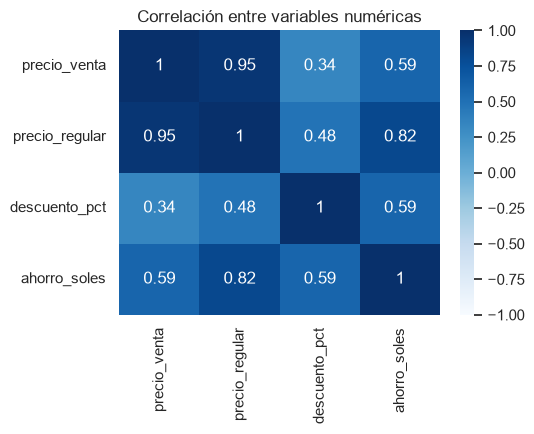

In [21]:
# Matriz de correlación (técnica fuera de U3_L2–U3_L6; justificada en la portada)
num = df[["precio_venta", "precio_regular", "descuento_pct", "ahorro_soles"]]
corr = num.corr().round(2)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(corr, annot=True, cmap="Blues", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()

**Interpretación.** `precio_venta` y `precio_regular` están muy correlacionadas (0,95): aportan casi la misma información. `precio_regular` y `ahorro_soles` también (0,82), porque el ahorro es la resta de ambos precios. `descuento_pct` es la menos redundante (0,34 a 0,59 con las demás).

**Decisión.** Se conservan todas las columnas, porque cada una responde a un objetivo del proyecto. En modelos o agrupamientos (por ejemplo, el K-Means de P4) no deben usarse juntas `precio_venta` y `precio_regular`.

## 6. Transformación

El precio de venta tiene una asimetría de 6,60: pocos productos muy caros dominan la media. Se prueban tres transformaciones sobre `precio_venta` y se compara su efecto:

- **`log1p`**: reduce la asimetría y es seguro con precios mayores que cero.
- **Min-max** y **z-score**: reescalan, pero no deberían cambiar la forma de la distribución; se prueban solo para comprobarlo.

Los booleanos se conservan como `bool` en el CSV, que es lo que acordó el equipo en el contrato de datos.

asimetría (skew):
original    6.60
log1p       1.11
min-max     6.60
z-score     6.60


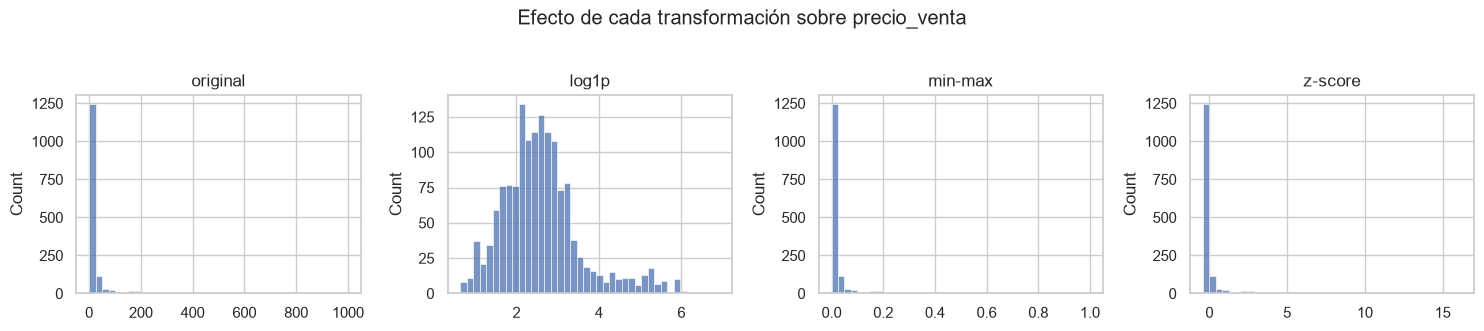

[6. Transformación de precio] precio_venta_log = log1p(precio_venta); min-max y z-score solo comparados en el notebook  |  filas: 1491 -> 1491


In [22]:
df["precio_venta_log"] = np.log1p(df["precio_venta"])

p = df["precio_venta"]
comparacion = pd.DataFrame({
    "original": p,
    "log1p": df["precio_venta_log"],
    "min-max": (p - p.min()) / (p.max() - p.min()),
    "z-score": (p - p.mean()) / p.std(),
})
print("asimetría (skew):")
print(comparacion.skew().round(2).to_string())

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, col in zip(axes, comparacion.columns):
    sns.histplot(comparacion[col], bins=40, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Efecto de cada transformación sobre precio_venta", y=1.03)
plt.tight_layout()
plt.show()

log("6. Transformación de precio",
    "precio_venta_log = log1p(precio_venta); min-max y z-score solo comparados en el notebook",
    "log1p reduce la asimetría fuerte del precio (la mediana es mucho menor que la media) y es seguro con precios > 0; min-max y z-score no cambian la forma de la distribución",
    "Guardar también min-max y z-score en el CSV (columnas redundantes)",
    len(df), len(df))

**Interpretación.** `log1p` reduce la asimetría de 6,60 a 1,11 y deja una distribución mucho más simétrica. Min-max y z-score mantienen la asimetría en 6,60: solo cambian la escala. **Decisión:** se guarda únicamente `precio_venta_log`; min-max y z-score se usaron solo para esta comparación y no se agregan al CSV.

## 7. Verificación final y exportación

Se comprueban los requisitos de calidad (más de 1000 registros, al menos 6 atributos, nulos ≤ 10 % por columna y sin duplicados) y que existan las cinco columnas que P1 debe entregar según el contrato de datos del equipo: `es_outlier_precio`, `precio_venta_log`, `macro_grupo`, `es_marca_propia` y `marca_agrupada`.

In [23]:
COLUMNAS_P1 = ["es_outlier_precio", "precio_venta_log", "macro_grupo", "es_marca_propia", "marca_agrupada"]
faltan = [c for c in COLUMNAS_P1 if c not in df.columns]

max_nulos = df.isna().mean().max() * 100
checks = {
    "> 1000 registros": len(df) > 1000,
    ">= 6 atributos": df.shape[1] >= 6,
    "<= 10 % de nulos por columna": max_nulos <= 10,
    "sin duplicados por url_producto": not df["url_producto"].duplicated().any(),
    "columnas del contrato P1 presentes": not faltan,
    "mismas filas que el dataset inicial": len(df) == len(df_inicial),
}
for nombre, ok in checks.items():
    print(("OK   " if ok else "FALLA"), nombre)
assert all(checks.values()), f"fallan requisitos: {[k for k, v in checks.items() if not v]}"

df.to_csv(OUT, index=False, encoding="utf-8")
print(f"\nexportado: {OUT}  ->  {df.shape[0]} filas x {df.shape[1]} columnas")
print(list(df.columns))

OK    > 1000 registros
OK    >= 6 atributos
OK    <= 10 % de nulos por columna
OK    sin duplicados por url_producto
OK    columnas del contrato P1 presentes
OK    mismas filas que el dataset inicial

exportado: ..\data\interim\plazavea_preprocesado.csv  ->  1491 filas x 17 columnas
['id_producto', 'nombre', 'marca', 'categoria', 'precio_venta', 'precio_regular', 'tiene_precio_oh', 'descuento_pct', 'url_producto', 'fecha_extraccion', 'tiene_descuento', 'ahorro_soles', 'es_outlier_precio', 'macro_grupo', 'es_marca_propia', 'marca_agrupada', 'precio_venta_log']


## 8. Bitácora de decisiones

Registro de cada decisión con su justificación, la alternativa que se descartó y el efecto en el número de filas. Alimenta directamente la sección 6 del informe.

In [24]:
df_bitacora = pd.DataFrame(bitacora)
df_bitacora.to_csv(DOCS / "bitacora_decisiones.csv", index=False, encoding="utf-8")
df_bitacora

,paso,decision,justificacion,alternativa_descartada,filas_antes,filas_despues,delta_filas
0,2.1 Verificación de precios y coherencia,"Sin cambios: no hay precios <= 0 ni regular < venta, y las 3 variables derivadas coinciden con el recálculo",El control queda registrado; se repite en el pipeline para detectar errores de extracción futuros,Recalcular y sobrescribir las columnas (innecesario: 0 diferencias),1491,1491,0
1,2.1.1 Verificación del precio máximo,"Se conserva 'Secador Alisador SIEGEN SG-B500 Blanco' (S/ 999.00): es un precio real, no un valor de relleno","Verificación manual en la página del producto (P1, 23/10/2026): vendido y despachado por Plaza Vea; precio de venta igual al regular, con opción de cuotas mediante tarjeta SIP",Tratarlo como valor centinela y convertirlo en nulo (descartado: el producto y su precio existen),1491,1491,0
2,2.2.1 Unificación de marcas,Se unifican 1 marca(s) con distintas escrituras (1 filas afectadas); GENÉRICO se conserva,Una misma marca escrita de dos formas contaría como dos marcas y distorsiona el ranking y la agrupación,Unificar también las familias BELL'S (se pierde la distinción entre fresco y envasado),1491,1491,0
3,2.3 Verificación manual de GENÉRICO,GENÉRICO se conserva en marca: 21 de 21 productos revisados son vendidos por terceros. Muestra en Cuidado Personal (sin GENÉRICO): 9 de 10 de mayores ahorros y 6 de 10 aleatorios son de terceros; control en otras categorías: 0 de 5,"Es un valor que muestra el sitio, no un dato faltante. Cada producto de terceros tiene una marca real distinta (prácticamente una marca por producto), así que recuperarlas no aporta a comparaciones ni a marca_agrupada y rompería la reproducibilidad (valores escritos a mano fuera del flujo). Las 3 mochilas de emergencia tienen 3 marcas distintas, ninguna es EMERGENCY KIT PERÚ","Convertir a nulo (groupby ignora los nulos sin avisar), renombrar a SIN MARCA, recuperar la marca a mano o borrar las 21 filas",1491,1491,0
4,3. Marcar outliers de precio,"Nueva columna es_outlier_precio (IQR por categoría, k = 1.5): 64 productos marcados, 0 eliminados",Son productos reales del catálogo; el IQR por categoría evita que Cuidado Personal marque como atípico lo que es normal en otras categorías,"Eliminarlos (pierde información real) o usar el IQR global (159 marcados, casi todos de Cuidado Personal)",1491,1491,0
5,4.2 Integración con dim_categoria,Left join por categoria -> macro_grupo (validate many_to_one),"Permite analizar por grandes familias (Frescos, Envasados, Bebidas, Cuidado Personal) además de por categoría",Inner join (podría perder filas si una categoría no está en la dimensión),1491,1491,0
6,4.3 Integración con dim_marca,"Left join por marca -> es_marca_propia (validate many_to_one): 263 productos de marca propia (BELL'S y sus líneas, PLAZA VEA, LA FLORENCIA); el resto de marcas se trata como no propia","Marca propia = marca de propiedad de PlazaVea según plazavea.com.pe/marcas-propias (consultada el 23/10/2026), más PLAZA VEA y las líneas de BELL'S por criterio de P1; permite comparar marca propia contra marcas nacionales (objetivo 5)",Inferir la marca propia por el nombre del producto (falsos positivos) o suponer que todo producto que vende PlazaVea es de marca propia,1491,1491,0
7,5. Reducción de marcas,"marca_agrupada = top 30 de marcas reales + GENÉRICO (nivel propio, 21 productos) + OTRAS (622 productos); marca original se conserva",Reduce la cardinalidad para análisis y gráficos legibles; GENÉRICO no ocupa un lugar del top porque no es una marca y se distingue de OTRAS; la marca original sigue disponible,"Top 30 incluyendo GENÉRICO (ocuparía el puesto 14), umbral por frecuencia mínima (≥ 10 productos) o conservar las 277 marcas (gráficos ilegibles)",1491,1491,0
8,6. Transformación de precio,precio_venta_log = log1p(precio_venta); min-max y z-score solo comparados en el notebook,log1p reduce la asimetría fuerte del precio (la mediana es mucho menor que la media) y es seguro con precios > 0; min-max 

## 9. Conclusiones de P1

**Qué se encontró**
- El dataset inicial no tiene nulos ni duplicados, pero sí defectos escondidos: una marca escrita de dos formas (`HORNIMAN S` / `HORNIMANS`) y 21 productos `GENÉRICO`.
- Los 21 productos `GENÉRICO` son todos de Cuidado Personal y todos de vendedores terceros. En una muestra, 15 de 20 productos de Cuidado Personal (sin `GENÉRICO`) también lo son; en otras categorías, 0 de 5.
- El precio de S/ 999 es real. El 4,3 % de los productos (64) tiene un precio extremo dentro de su categoría; ninguno se elimina.
- El 17,6 % de los productos (263) es de marca propia de PlazaVea.

**Qué se decidió y por qué**
- Todo se conserva y se marca; no se borra ninguna fila (1491 antes y después).
- Los límites de precio extremo se calculan por categoría, porque Cuidado Personal tiene otra escala de precios.
- `GENÉRICO` se mantiene como valor y queda fuera del top 30 de marcas, porque no es una marca.
- Solo se guarda `precio_venta_log` como transformación, porque min-max y z-score no corrigen la asimetría.

**Entrega a las otras partes**
- **P2:** `data/interim/plazavea_preprocesado.csv` (17 columnas, 1491 filas) y las funciones de `src/preprocessing.py`.
- **P3:** `es_outlier_precio` y `macro_grupo`, más la nota de que Cuidado Personal mezcla vendedores.
- **P4:** `es_marca_propia` y `marca_agrupada` (32 niveles). `GENÉRICO` y `OTRAS` no son marcas y deben excluirse de los rankings.
- **P5:** `docs/bitacora_decisiones.csv`, `docs/cifras_oficiales.csv` y `docs/evidencia_vendedor.csv`.

**Limitaciones**
- Foto de un solo día (22/09/2026): no permite análisis temporal.
- Se extrajeron los primeros 150 productos por categoría, sin muestreo aleatorio; la categoría Limpieza quedó fuera.
- El catálogo mezcla productos de PlazaVea y de terceros, y el dataset no incluye una columna de vendedor.
- La clasificación de marca propia depende de la página oficial consultada el 23/10/2026.
- El 41,7 % de los productos queda en `OTRAS` en `marca_agrupada`.